<a href="https://colab.research.google.com/github/24sahil25-source/BA305-BoardGameGeek-Fall2026/blob/main/notebooks/06_neural_network_rowan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 2: a neural network to predict a board game's average rating

Follows the Session 17 lab (*lab8_Neural_Networks*, predicting Toyota Corolla prices) step by step, with `MLPRegressor` predicting a game's `average` rating instead of a car's price.

Three changes from the lab, all required by the project's ground rules:

- **Missing values.** The lab's data had none; ours does. As settled by task 1 (notebook 05), every game is kept and missing inputs are filled with the training median, plus a 0/1 column saying "this was missing".
- **Cross-validation instead of a validation set.** The lab compared models on its 30% validation cars. Here the 30% are test games, scored **once** at the end, so models are compared by 5-fold cross-validation on the training games. Imputer and scaler sit inside a `Pipeline`, so they are refitted on the training folds each time.
- **Tuning.** Two of the lab's settings, the architecture and the activation function, are tuned together by cross-validation.

## Setup

In [1]:
# --- Rowan John: task 2, a neural network (MLPRegressor) to predict a game's average rating, following the Session 17 lab ---
# [AI-assisted] Claude Code, 2026-11-10. Every code and markdown cell in this notebook was generated with Claude Code from the Session 17 lab and notebook 04; reviewed and edited by Rowan John.
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, cross_val_predict, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.exceptions import ConvergenceWarning
warnings.simplefilter("ignore", ConvergenceWarning)  # the solver warns when it hits max_iter; we check training steps ourselves

## Part 1: Preparing the data

In [2]:
# [AI-assisted] Claude Code, 2026-11-10. Same loading cell as notebooks 02 to 05; reviewed and edited by Rowan John.
BASE = "https://raw.githubusercontent.com/24sahil25-source/BA305-BoardGameGeek-Fall2026/main/data/"
games = pd.read_csv(BASE + "bgg_clean.csv")
print(games.shape)

FIG_DIR = "../figures" if os.path.isdir("../figures") else "."

(21631, 24)


### The variables we use

The outcome is `average`, the mean user rating (1 to 10). The predictors are notebook 04's 43 inputs, all known before a game is released:

| Inputs | What they are |
|---|---|
| `yearpublished` | Year of publication |
| `minplayers`, `maxplayers` | Player-count range (log10, as in notebook 04, because a few games allow hundreds of players) |
| `minplaytime`, `maxplaytime` | Play-time range in minutes (log10, for the same reason) |
| `minage` | Publisher's minimum age |
| `n_mechanics`, `n_categories` | Number of mechanics and categories listed |
| 20 `mech_` and 15 `cat_` columns | 0/1 dummy columns for the most common mechanics and categories |

**Left out:** `rank`, `bayes_average`, `users_rated`, `owned`, `trading`, `wanting` and `wishing` are measured after release, so using them would be leakage. `id` and `name` are labels, not measurements.

The mechanic and category columns are the **dummy columns** step from the lab: each game's list becomes one 0/1 column per mechanic or category.

**Split first.** As in the lab, 30% of the games are held out before anything is fitted, with `random_state=1`. The list of most common mechanics and categories is counted on the training games only.

In [3]:
# [AI-assisted] Claude Code, 2026-11-10. 70/30 split, then notebook 04's input builder with the dummy columns taken from the training games; reviewed and edited by Rowan John.
train_df, test_df = train_test_split(games, test_size=0.3, random_state=1)

numeric_cols = ["yearpublished", "minplayers", "maxplayers", "minplaytime", "maxplaytime", "minage", "n_mechanics", "n_categories"]
top_mech = train_df["boardgamemechanic"].str.get_dummies(sep="|").mean().sort_values(ascending=False).head(20).index
top_cat = train_df["boardgamecategory"].str.get_dummies(sep="|").mean().sort_values(ascending=False).head(15).index

def build_inputs(frame):
    X = frame[numeric_cols].copy()
    for col in ["minplayers", "maxplayers", "minplaytime", "maxplaytime"]:
        X[col] = np.log10(X[col])
    mech = frame["boardgamemechanic"].str.get_dummies(sep="|").reindex(columns=top_mech, fill_value=0).add_prefix("mech_")
    cat = frame["boardgamecategory"].str.get_dummies(sep="|").reindex(columns=top_cat, fill_value=0).add_prefix("cat_")
    return pd.concat([X, mech, cat], axis=1)

X_train_nonscaled, X_test_nonscaled = build_inputs(train_df), build_inputs(test_df)
y_train_nonscaled, y_test_nonscaled = train_df["average"], test_df["average"]
print("training games:", len(X_train_nonscaled), "| test games:", len(X_test_nonscaled), "| inputs:", X_train_nonscaled.shape[1])
print("training games with at least one missing input:", X_train_nonscaled.isna().any(axis=1).sum())

training games: 15141 | test games: 6490 | inputs: 43
training games with at least one missing input: 2530


### Filling in missing values, then scaling every column to 0–1

Two steps, both learned from the training games only and then applied unchanged to any other games:

1. **Impute** (task 1's choice): fill each missing input with the training median, and add a 0/1 column per input saying it was missing.
2. **MinMax scaling**, exactly as in the lab: $x_{scaled} = (x - x_{min}) / (x_{max} - x_{min})$, so year (around 2000) does not drown out the 0/1 columns.

They are chained in a `Pipeline` with the network. During cross-validation the whole pipeline is refitted on each set of training folds, so the held-out fold never influences the imputer or the scaler.

**Scaling the rating.** The lab scaled Price to 0–1 because a new network's first predictions are near 0. We do the same for the rating, using the rating scale's own limits, 1 and 10, instead of a fitted scaler, so nothing is learned from the data and nothing can leak between folds. `to_ratings` converts the network's predictions back, like the lab's `to_euros`.

In [4]:
# [AI-assisted] Claude Code, 2026-11-10. Rating scaling helpers, the lab's to_euros adapted to ratings; reviewed and edited by Rowan John.
def to_scaled(ratings):
    return (np.asarray(ratings) - 1) / 9

def to_ratings(scaled):
    # Undo the 0-1 scaling so predictions are back on the 1-10 rating scale.
    return np.asarray(scaled) * 9 + 1

y_train = to_scaled(y_train_nonscaled)
print("scaled training ratings: smallest", round(y_train.min(), 3), "  largest", round(y_train.max(), 3))

scaled training ratings: smallest 0.004   largest 0.952


In [5]:
# [AI-assisted] Claude Code, 2026-11-10. Pipeline factory: impute, MinMax scale, then the model; reviewed and edited by Rowan John.
def make_pipeline(model):
    return Pipeline([
        ("impute", SimpleImputer(strategy="median", add_indicator=True)),
        ("scale", MinMaxScaler()),
        ("model", model),
    ])

### How good is a model?

The lab's `regression_report` printed the validation errors. Ours does the same from **cross-validation**: every training game is predicted once by a model that did not see it (5 folds, `cross_val_predict`), the predictions are converted back to ratings, and we report

- **RMSE**: roughly how far off a typical prediction is, in rating points. Lower is better; it is the number we compare models on.
- **MAE**: the average absolute error, less affected by a few big misses.
- **R²**: the share of the variation in ratings the model explains. 0 means no better than predicting the average for every game.

For a network it also reports the **training steps** taken (`n_iter_`) when fitted on all training games, the lab's check for a network that quit early.

In [6]:
# [AI-assisted] Claude Code, 2026-11-10. The lab's regression_report, computed from 5-fold cross-validated predictions on the training games; reviewed and edited by Rowan John.
folds = KFold(n_splits=5, shuffle=True, random_state=0)
actual = y_train_nonscaled.values

def regression_report(model, name):
    pred = to_ratings(cross_val_predict(model, X_train_nonscaled, y_train, cv=folds, n_jobs=-1))
    row = {"CV RMSE": np.sqrt(mean_squared_error(actual, pred)), "CV MAE": mean_absolute_error(actual, pred), "CV R2": r2_score(actual, pred)}
    if isinstance(model.named_steps["model"], MLPRegressor):
        row["training steps"] = model.fit(X_train_nonscaled, y_train).named_steps["model"].n_iter_
    summary[name] = row
    return pd.Series(row).round(4)

summary = {}

## Part 2: A first neural network

### Yardstick: predict the average rating for every game

The lab's yardstick, as scikit-learn's `DummyRegressor`. Any model worth using must beat it.

In [7]:
# [AI-assisted] Claude Code, 2026-11-10. DummyRegressor yardstick; reviewed and edited by Rowan John.
regression_report(make_pipeline(DummyRegressor()), "Predict the average (DummyRegressor)")

CV RMSE    0.9327
CV MAE     0.7290
CV R2     -0.0002
dtype: float64

### One hidden layer with 2 nodes

The lab's first network and settings: `hidden_layer_sizes=(2,)`, `activation="logistic"` (the sigmoid from the slides), `solver="lbfgs"`, `random_state=1`.

In [8]:
# [AI-assisted] Claude Code, 2026-11-10. The lab's first network; reviewed and edited by Rowan John.
nnet = make_pipeline(MLPRegressor(hidden_layer_sizes=(2,), activation="logistic", solver="lbfgs", random_state=1))
regression_report(nnet, "NN (2), logistic")

CV RMSE            0.7669
CV MAE             0.5885
CV R2              0.3237
training steps    50.0000
dtype: float64

### Compare to linear regression

The same inputs, the same pipeline and the same folds.

In [9]:
# [AI-assisted] Claude Code, 2026-11-10. Linear regression on the same pipeline; reviewed and edited by Rowan John.
regression_report(make_pipeline(LinearRegression()), "Linear regression")

CV RMSE    0.7541
CV MAE     0.5757
CV R2      0.3462
dtype: float64

**Takeaway:** the lab's first network, (2,) with default settings, has a cross-validated RMSE of 0.767. That clearly beats predicting the average (0.933), but it is *worse* than linear regression (0.754). It stopped after only 50 training steps. In the lab the small network beat linear regression straight away; here it needs the fix in Part 3.

## Part 3: Changing the architecture

In [10]:
# [AI-assisted] Claude Code, 2026-11-10. The lab's other three architectures with default settings; reviewed and edited by Rowan John.
for h in [(5,), (2, 2, 2), (5, 5, 5)]:
    nnet = make_pipeline(MLPRegressor(hidden_layer_sizes=h, activation="logistic", solver="lbfgs", random_state=1))
    print(h, regression_report(nnet, f"NN {h}, logistic").to_dict())

(5,) {'CV RMSE': 0.7736, 'CV MAE': 0.5956, 'CV R2': 0.3118, 'training steps': 36.0}


(2, 2, 2) {'CV RMSE': 0.9297, 'CV MAE': 0.7264, 'CV R2': 0.0061, 'training steps': 1.0}


(5, 5, 5) {'CV RMSE': 0.9321, 'CV MAE': 0.7287, 'CV R2': 0.0009, 'training steps': 3.0}


### Diagnosing a network that failed to train

The (5,) network quit after 36 steps (CV RMSE 0.774). The two deep networks **failed to train outright**: (2, 2, 2) stopped after 1 step and (5, 5, 5) after 3, and both score 0.930 to 0.932, the same as predicting the average for every game (R² about 0). This is exactly the failure the lab diagnoses: the first steps barely improve the fit, so the solver gives up. As in the lab, the step limit was not the problem, since 200 steps were never reached.

**The lab's fix:** lower `tol` to `1e-8` so even tiny improvements count as progress, and raise `max_iter` to 2000 so there is room to finish.

In [11]:
# [AI-assisted] Claude Code, 2026-11-10. The lab's fix: tol=1e-8 and max_iter=2000, for all four architectures; reviewed and edited by Rowan John.
for h in [(2,), (5,), (2, 2, 2), (5, 5, 5)]:
    nnet = make_pipeline(MLPRegressor(hidden_layer_sizes=h, activation="logistic", solver="lbfgs", tol=1e-8, max_iter=2000, random_state=1))
    print(h, regression_report(nnet, f"NN {h}, logistic, tol 1e-8").to_dict())

(2,) {'CV RMSE': 0.7114, 'CV MAE': 0.5349, 'CV R2': 0.4181, 'training steps': 1738.0}


(5,) {'CV RMSE': 0.7131, 'CV MAE': 0.5375, 'CV R2': 0.4152, 'training steps': 2000.0}


(2, 2, 2) {'CV RMSE': 0.7122, 'CV MAE': 0.5389, 'CV R2': 0.4167, 'training steps': 1476.0}


(5, 5, 5) {'CV RMSE': 0.7046, 'CV MAE': 0.5326, 'CV R2': 0.4291, 'training steps': 1090.0}


**What about a different activation function?** As in the lab, ReLU, `max(0, x)`, with the same fix.

In [12]:
# [AI-assisted] Claude Code, 2026-11-10. ReLU with the lab's fix; reviewed and edited by Rowan John.
nnet = make_pipeline(MLPRegressor(hidden_layer_sizes=(5, 5, 5), activation="relu", solver="lbfgs", tol=1e-8, max_iter=2000, random_state=1))
regression_report(nnet, "NN (5, 5, 5), relu, tol 1e-8")

CV RMSE              0.7553
CV MAE               0.5794
CV R2                0.3440
training steps    2000.0000
dtype: float64

**Takeaway:** the fix works here as in the lab. With `tol=1e-8` all four logistic networks now beat linear regression (0.754): (2,) 0.711, (5,) 0.713, (2, 2, 2) 0.712 and (5, 5, 5) 0.705, after 1,090 to 2,000 steps. As in the lab, the architecture matters much less than whether training was allowed to finish. **ReLU did not help:** even with the fix, (5, 5, 5) with ReLU scores 0.755, no better than linear regression.

## Part 4: Tuning two settings together

The project asks for at least two hyperparameters tuned by cross-validation. We tune the two the lab varied: the **architecture** (the lab's four plus one layer of 10 nodes) and the **activation** (logistic or ReLU), keeping the lab's fix (`tol=1e-8`, `max_iter=2000`). `GridSearchCV` tries every combination on the same 5 folds.

In [13]:
# [AI-assisted] Claude Code, 2026-11-10. GridSearchCV over hidden_layer_sizes and activation; reviewed and edited by Rowan John.
param_grid = {
    "model__hidden_layer_sizes": [(2,), (5,), (10,), (2, 2, 2), (5, 5, 5)],
    "model__activation": ["logistic", "relu"],
}
nnet = make_pipeline(MLPRegressor(solver="lbfgs", tol=1e-8, max_iter=2000, random_state=1))
grid = GridSearchCV(nnet, param_grid, cv=folds, scoring="neg_root_mean_squared_error", n_jobs=-1)
grid.fit(X_train_nonscaled, y_train)

# CV RMSE is on the 0-1 scale; multiplying by 9 puts it back in rating points.
results = pd.DataFrame(grid.cv_results_)
results["architecture"] = results["param_model__hidden_layer_sizes"].astype(str)
table = (-9 * results.pivot(index="architecture", columns="param_model__activation", values="mean_test_score")).round(4)
print("best settings:", grid.best_params_, "| CV RMSE:", round(-9 * grid.best_score_, 4))
table

best settings: {'model__activation': 'logistic', 'model__hidden_layer_sizes': (5, 5, 5)} | CV RMSE: 0.7041


param_model__activation,logistic,relu
architecture,,
"(10,)",0.7147,0.7277
"(2, 2, 2)",0.7118,0.9325
"(2,)",0.7109,0.7537
"(5, 5, 5)",0.7041,0.7553
"(5,)",0.7128,0.7373


**Takeaway:** the best setting is the lab's deepest network, **(5, 5, 5) with logistic activation** (CV RMSE 0.704). The other logistic networks are within 0.011 of it (0.711 to 0.715). ReLU is worse for every architecture (0.728 to 0.755), and (2, 2, 2) with ReLU failed to train at all (0.933, the average).

### Summary

In [14]:
# [AI-assisted] Claude Code, 2026-11-10. Summary table of every model above, the lab's summary table; reviewed and edited by Rowan John.
pd.DataFrame(summary).T.round(3)

,CV RMSE,CV MAE,CV R2,training steps
Predict the average (DummyRegressor),0.933,0.729,-0.000,NaN
"NN (2), logistic",0.767,0.589,0.324,50.0
Linear regression,0.754,0.576,0.346,NaN
"NN (5,), logistic",0.774,0.596,0.312,36.0
"NN (2, 2, 2), logistic",0.930,0.726,0.006,1.0
"NN (5, 5, 5), logistic",0.932,0.729,0.001,3.0
"NN (2,), logistic, tol 1e-8",0.711,0.535,0.418,1738.0
"NN (5,), logistic, tol 1e-8",0.713,0.537,0.415,2000.0
"NN (2, 2, 2), logistic, tol 1e-8",0.712,0.539,0.417,1476.0
"NN (5, 5, 5), logistic, tol 1e-8",0.705,0.533,0.429,1090.0


As in the lab's summary: the default settings left every network no better than linear regression, and the two deep ones learned nothing. Once training is allowed to finish, every logistic network beats linear regression by about 0.04 to 0.05 rating points, and the architecture changes the result by only about 0.01.

## Part 5: Score the test games once

The tuned network, linear regression and the yardstick, each fitted on all 15,141 training games and scored once on the 6,490 test games.

In [15]:
# [AI-assisted] Claude Code, 2026-11-10. Fit the final models on the training games and score once on the test games; reviewed and edited by Rowan John.
final_models = {
    "Predict the average (DummyRegressor)": make_pipeline(DummyRegressor()),
    "Linear regression": make_pipeline(LinearRegression()),
    "Neural network (tuned)": grid.best_estimator_,
}
test_rows = {}
for name, m in final_models.items():
    if name != "Neural network (tuned)":
        m.fit(X_train_nonscaled, y_train)
    pred = to_ratings(m.predict(X_test_nonscaled))
    test_rows[name] = {"test RMSE": np.sqrt(mean_squared_error(y_test_nonscaled, pred)), "test MAE": mean_absolute_error(y_test_nonscaled, pred),
                       "test R2": r2_score(y_test_nonscaled, pred)}
test_table = pd.DataFrame(test_rows).T
test_table.round(3)

,test RMSE,test MAE,test R2
Predict the average (DummyRegressor),0.922,0.725,-0.000
Linear regression,0.744,0.574,0.348
Neural network (tuned),0.724,0.553,0.383


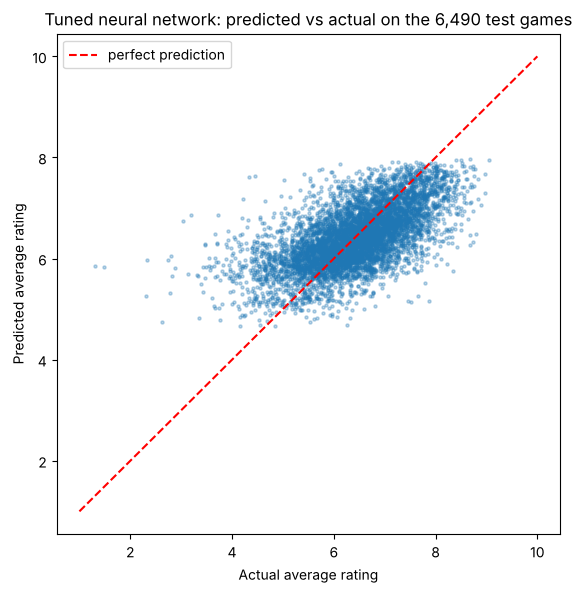

predictions run from 4.66 to 7.97 | actual ratings from 1.31 to 9.05


In [16]:
# [AI-assisted] Claude Code, 2026-11-10. Predicted against actual rating for the tuned network, as in the lab; reviewed and edited by Rowan John.
pred = to_ratings(grid.best_estimator_.predict(X_test_nonscaled))
ax = pd.DataFrame({"actual": y_test_nonscaled.values, "predicted": pred}).plot.scatter(x="actual", y="predicted", s=5, alpha=0.3, figsize=(6.5, 6.5))
ax.plot([1, 10], [1, 10], color="red", linestyle="--", label="perfect prediction")
ax.set_title(f"Tuned neural network: predicted vs actual on the {len(pred):,} test games")
ax.set_xlabel("Actual average rating")
ax.set_ylabel("Predicted average rating")
ax.legend()
plt.savefig(os.path.join(FIG_DIR, "06_nn_predicted_vs_actual.png"), dpi=200, bbox_inches="tight")
plt.show()
print("predictions run from", round(pred.min(), 2), "to", round(pred.max(), 2), "| actual ratings from", round(y_test_nonscaled.min(), 2), "to", round(y_test_nonscaled.max(), 2))

### Checking the final fit

The lab's check for a network that quit early, applied to the tuned network as refitted on all 15,141 training games: how many training steps it took, and how well it fits the training games themselves. This uses the training games only.

In [17]:
# [AI-assisted] Claude Code, 2026-11-10. Training steps and training RMSE of the final refit, compared with the same network inside each cross-validation fold; reviewed and edited by Rowan John.
final_net = grid.best_estimator_
train_pred = to_ratings(final_net.predict(X_train_nonscaled))
print("final refit: training steps", final_net.named_steps["model"].n_iter_, "of", final_net.named_steps["model"].max_iter,
      "| training RMSE", round(np.sqrt(mean_squared_error(actual, train_pred)), 4),
      "| training predictions from", round(train_pred.min(), 2), "to", round(train_pred.max(), 2))

final refit: training steps 1090 of 2000 | training RMSE 0.7156 | training predictions from 4.61 to 8.02


**Takeaway:** on the 6,490 test games the tuned network has RMSE **0.724**, MAE **0.553** and R² **0.383**. It beats linear regression (0.744, 0.574, 0.348) and the yardstick (0.922), but by less than cross-validation suggested (0.704). Its predictions are squeezed into 4.7 to 8.0, while actual ratings run from 1.3 to 9.1. The check below shows why.

**The final refit quit early.** Refitted on all training games, (5, 5, 5) stopped after 1,090 of its 2,000 allowed steps, with a training RMSE of 0.716. That training RMSE is worse than the network's own cross-validated RMSE on games it had not seen (0.704), which a network that trained properly would not do. So this is the lab's "failed to train" problem again, in a milder form: the deep network got stuck in this one fit. We noticed it only after scoring the test games. To keep the test score honest it is reported as it came out, not re-tuned. Checking the final fit's training steps *before* scoring the test games would have caught it, and that is the lesson to carry into task 10.

## What did not work

- **The lab's default settings failed.** With `tol=1e-4` and `max_iter=200` no network beat linear regression, and both three-layer networks stopped after 1 to 3 steps and predicted the average. Lowering `tol` to `1e-8` fixed it, as in the lab.
- **ReLU did not help.** It was worse than logistic for every architecture, and (2, 2, 2) with ReLU failed to train.
- **The tuned deep network's final refit got stuck.** (5, 5, 5) did best in cross-validation (0.704), but its refit on all training games stopped early (training RMSE 0.716) and scored 0.724 on the test games. The smallest network, (2,), was only 0.007 worse in cross-validation, and the lab's summary found the same: deeper networks are where training fails. Preferring the simplest network close to the best, or checking the final fit before the test, would have been the safer choice.

Comparing the network with the tree and k-NN on these same games is task 10.